### Advanced vizualisation

#### Load data

In [1]:
import pandas as pd
import numpy as np
from util.data_aquisition import generate
from util.data_frame import get_data_frame
import math

In [2]:
data = generate()

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2018-2019
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2018-2019
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/play_off/2019-2020
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2019-2020
Data is available on your system. Will be loaded from: /

In [3]:
df = get_data_frame(data)

In [4]:
df.head()

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate
0,2016030185,P,4,Edmonton Oilers,left,San Jose Sharks,Shot,Backhand,2017-04-21T02:45:20Z,1,00:19,San Jose Sharks,NaN,NaN,Joe Pavelski,Cam Talbot,-56.0,23.0
1,2016030185,P,9,Edmonton Oilers,left,San Jose Sharks,Shot,Wrist Shot,2017-04-21T02:45:40Z,1,00:39,Edmonton Oilers,NaN,NaN,Milan Lucic,Martin Jones,59.0,15.0
2,2016030185,P,11,Edmonton Oilers,left,San Jose Sharks,Shot,Slap Shot,2017-04-21T02:46:01Z,1,01:00,San Jose Sharks,NaN,NaN,Jannik Hansen,Cam Talbot,-34.0,-30.0
3,2016030185,P,17,Edmonton Oilers,left,San Jose Sharks,Shot,Snap Shot,2017-04-21T02:47:55Z,1,02:03,San Jose Sharks,NaN,NaN,Justin Braun,Cam Talbot,-33.0,26.0
4,2016030185,P,18,Edmonton Oilers,left,San Jose Sharks,Shot,Snap Shot,2017-04-21T02:48:04Z,1,02:12,Edmonton Oilers,NaN,NaN,Oscar Klefbom,Martin Jones,45.0,19.0


#### Prepare the data

In [5]:
def transform_X(row):
    '''
    Given a row of the original data frame, this function transforms the coordinate X depending on the position of
    the teams in the rink. Since at the end the data is presented in a half-rink (we arbitrarily choose that
    this is the right half of the rink), when the attacking team plays on the right side of the rink , i.e
    the opponent's goal is on the left side, we need to flip the x coordinate.
    '''
    if str(row['Home_Rink']) == 'nan': #In case the rinkside information is not available, we assume the shot
        #is taken from the side that is the closest to the opponent's goal.
        return np.absolute(row['X_Coordinate'])

    else: #Otherwise we use rinkside information to determine whether to flip X coordinate as described above.
        if row['Home_Team'] == row['Team_Attack']:
            if row['Home_Rink'] == 'right':
                return -(row['X_Coordinate'])
            else:
                return row['X_Coordinate']
        else:
            if row['Home_Rink'] == 'left':
                return -(row['X_Coordinate'])
            else:
                return row['X_Coordinate']

In [6]:
#Applying the transformation and filtering data
df['X_Transformed'] = df.apply(transform_X, axis=1)
df = df[df['X_Transformed'] >= 0] #Since some shots are taken really far away from the opponent's goal (in the
#attacking team's side), after transformation, those shots will have a negative X coordinate. Since we only
#need positive X coordinates and these shots are very rare and might also be an error in the API, we will
#ommit them.
df['season'] = df.Game_ID.map(lambda x: str(x)[:4]) #season is needed for grouping later

In [43]:
#Since coordinates are continuous, to produce a heat map over the right side of the rink, we need to bin them
#We define the following constant as bin width in feet
WIDTH = 2.5
df['X_bin'] = df.X_Transformed.map(lambda x: int(np.floor(x / WIDTH) * WIDTH) if not math.isnan(x) else np.nan)
df['Y_bin'] = df.Y_Coordinate.map(lambda x: int(np.floor(x / WIDTH) * WIDTH) if not math.isnan(x) else np.nan)

In [44]:
df.head()

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,...,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate,X_Transformed,season,X_bin,Y_bin
0,2016030185,P,4,Edmonton Oilers,left,San Jose Sharks,Shot,Backhand,2017-04-21T02:45:20Z,1,...,NaN,NaN,Joe Pavelski,Cam Talbot,-56.0,23.0,56.0,2016,55,22.0
1,2016030185,P,9,Edmonton Oilers,left,San Jose Sharks,Shot,Wrist Shot,2017-04-21T02:45:40Z,1,...,NaN,NaN,Milan Lucic,Martin Jones,59.0,15.0,59.0,2016,57,15.0
2,2016030185,P,11,Edmonton Oilers,left,San Jose Sharks,Shot,Slap Shot,2017-04-21T02:46:01Z,1,...,NaN,NaN,Jannik Hansen,Cam Talbot,-34.0,-30.0,34.0,2016,32,-30.0
3,2016030185,P,17,Edmonton Oilers,left,San Jose Sharks,Shot,Snap Shot,2017-04-21T02:47:55Z,1,...,NaN,NaN,Justin Braun,Cam Talbot,-33.0,26.0,33.0,2016,32,25.0
4,2016030185,P,18,Edmonton Oilers,left,San Jose Sharks,Shot,Snap Shot,2017-04-21T02:48:04Z,1,...,NaN,NaN,Oscar Klefbom,Martin Jones,45.0,19.0,45.0,2016,45,17.0


In [ ]:
#For each season, and each (x,y)-bin (or pixel), we calculate the average shot number per hour among the whole
# league.
#That would be the total count of shots played at that position for that season, divided by the number
#of hours played that season. Since a game is an hour (assumption) that would be the number of games,
#i.e the number of distinct game ids in the whole season.
n_shots_per_pixel_and_season = df.groupby(['season', 'X_bin', 'Y_bin'])["Game_ID"].count()
n_games_per_season = df.groupby('season')["Game_ID"].nunique() #Here we don't group by x and y bins, since
#We need the total number of games of the season, and not just the games where a shot was made from a particular
#x,y position.
#Since we didn't group by x and y in the second data frame, we need to broadcast both data frames in order to
#devide one by the other, i.e we need to make n_games_per_season have the same index as n_shots_per_pixel_and_season
#By repeating the data accordingly. This can be done using align.
n_shots_per_pixel_and_season, n_games_per_season = n_shots_per_pixel_and_season.align(n_games_per_season)
league_average = n_shots_per_pixel_and_season / (n_games_per_season*2) #It's important to divide by two here
# because otherwise, for each pixel we would be accounting for the number of shots of two teams who play the game
#and not only one team.
league_average = league_average.rename("avg_n_shots")

In [ ]:
#Dowing the same as above but for each team individually: grouping by team first
n_shots_per_team_pixel_and_season = df.groupby(['Team_Attack', 'season', 'X_bin', 'Y_bin'])["Game_ID"].count()
n_games_per_team_and_season = df.groupby(['Team_Attack', 'season'])["Game_ID"].nunique()
n_shots_per_team_pixel_and_season, n_games_per_team_and_season = n_shots_per_team_pixel_and_season.align(n_games_per_team_and_season)
team_averages = n_shots_per_team_pixel_and_season / n_games_per_team_and_season
team_averages = team_averages.rename("avg_n_shots")

In [ ]:
#Broadcasting team_averages and league average to calculate the excess shot rate
team_averages, league_average = team_averages.align(league_average)

In [ ]:
excess_shot_rph = team_averages-league_average
excess_shot_rph = excess_shot_rph.rename("excess_shot_rph")

In [ ]:
import plotly.graph_objects as go
import plotly.express as px
import matplotlib.image as mpimg
from skimage import io

In [ ]:
image = io.imread('figures/nhl_rink.png')

In [ ]:
def create_interactive_figure(season: str):
    #Setting up the field
    fig = px.imshow(image, x=np.linspace(-100, 100, image.shape[1]), y=np.linspace(42.5, -42.5, image.shape[0]),
                   title = f"Excess shots map compared to league average, season {season}. Please select team.")
    fig.update_xaxes(range = (0,100), dtick=10)
    
    #Adding a heatmap for each team
    teams = excess_shot_rph.index.get_level_values(level=3).unique()
    for team in teams:
        pivoted_df = excess_shot_rph[season,:,:,team].reset_index().pivot(index='Y_bin', columns='X_bin', values = 'excess_shot_rph')
        heat_map = go.Heatmap(z=pivoted_df, x0=0+WIDTH/2, dx=WIDTH, y0=-42.5+WIDTH/2, dy=WIDTH, zsmooth="best",
                          colorscale='RdBu', reversescale=True, zmid=0, colorbar_title="Excess shots per hour", visible= False)
        fig.add_trace(heat_map)
    
    #Dropdown menu to hide all teams data but one
    buttons= [
        dict(label = team,
                  method = 'update',
                  args = [{'visible': [True]+[team == team_selected for team_selected in teams]},
                          {'title': f"Excess shots map compared to league average for {team}, season {season}."}])
        for team in teams
    ]

    fig.update_layout(
        updatemenus=[go.layout.Updatemenu(
        active=-1,
        buttons=buttons)])

    
    return fig
    

In [ ]:
create_interactive_figure("2016")

In [ ]:
create_interactive_figure("2017")

In [ ]:
create_interactive_figure("2018")

In [ ]:
create_interactive_figure("2019")

In [ ]:
create_interactive_figure("2020")


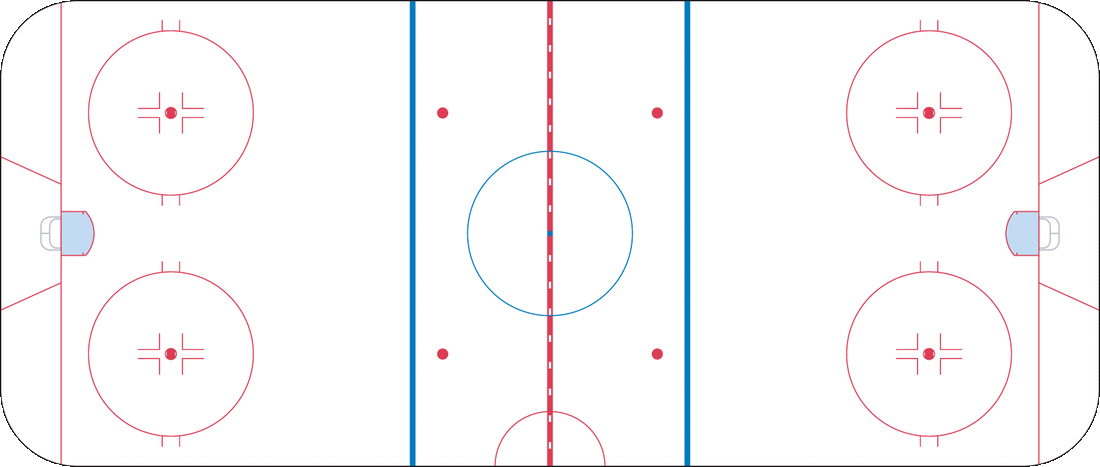

In [180]:
create_interactive_figure("2019")


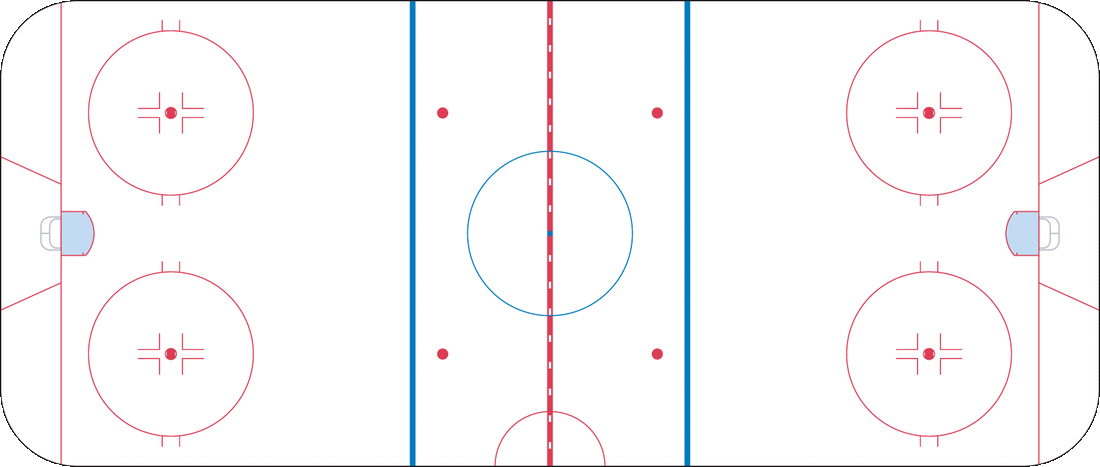

In [181]:
create_interactive_figure("2020")